# Task 4: Nonparamentric Model — the k-Nearest Neighbors Regressor

### Imports

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.utils import resample
from skl2onnx import convert_sklearn
from skl2onnx.common.data_types import FloatTensorType
import seaborn as sns
from sklearn.neighbors import KNeighborsRegressor

### Auxiliary functions

In [22]:
# got this code from https://stackoverflow.com/questions/17315737/split-a-large-pandas-dataframe or https://www.statology.org/pandas-chunk-dataframe/
def fixed_size_subframes(data):
    n = 257
    return [data[i : i + n].copy() for i in range(0, data.shape[0], n)]


def remove_useless_rows(subframes):
    cleaned_subframes = []
    
    for df in subframes:
        # Identify rows where all values except for 'Id' are 0
        mask = (df.drop(columns=['Id']) != 0).any(axis=1)
        
        # Filter out the "useless" rows
        cleaned_df = df[mask]
        
        # Append the cleaned dataframe to the list
        if not cleaned_df.empty:
            cleaned_subframes.append(cleaned_df)
    
    return cleaned_subframes


def augment_dataset(df, features_to_drop=[], enable_euclidian_dist=False, enable_angles=False, enable_polars=False):
    # Calculate Euclidean distances between points (x_1, y_1), (x_2, y_2), and (x_3, y_3)
    if enable_euclidian_dist:
        df['dist_12'] = np.sqrt((df['x_2'] - df['x_1'])**2 + (df['y_2'] - df['y_1'])**2)
        df['dist_23'] = np.sqrt((df['x_3'] - df['x_2'])**2 + (df['y_3'] - df['y_2'])**2)
        df['dist_13'] = np.sqrt((df['x_3'] - df['x_1'])**2 + (df['y_3'] - df['y_1'])**2)

    # Calculate the angles between the points
    if enable_angles:
        df['angle_1'] = calculate_angle(df['x_1'], df['y_1'], df['x_2'], df['y_2'], df['x_3'], df['y_3'])
        df['angle_2'] = calculate_angle(df['x_2'], df['y_2'], df['x_1'], df['y_1'], df['x_3'], df['y_3'])
        df['angle_3'] = calculate_angle(df['x_3'], df['y_3'], df['x_1'], df['y_1'], df['x_2'], df['y_2'])

    # Calculate polar coordinates for each point
    if enable_polars:
        df['r_1'], df['theta_1'] = calculate_polar_coordinates(df['x_1'], df['y_1'])
        df['r_2'], df['theta_2'] = calculate_polar_coordinates(df['x_2'], df['y_2'])
        df['r_3'], df['theta_3'] = calculate_polar_coordinates(df['x_3'], df['y_3'])

    return df.drop(columns=features_to_drop)


def create_features_and_targets(subframes, features_to_drop=[], enable_euclidian_dist=False, enable_angles=False, enable_polars=False):
    feature_labels = ['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3']
    target_labels = ['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3']
    X_chunks = []
    y_chunks = []
    
    for df in subframes:        
        # Get initial conditions as numpy array
        initial_conditions = df.iloc[0][feature_labels].values
        
        # Use vectorized operations to create features
        time_values = df['t'].values
        initial_conditions_repeated = np.tile(initial_conditions, (len(df), 1))  # Repeat initial conditions for all rows
        X_chunk = np.column_stack((time_values, initial_conditions_repeated))  # Combine time with initial conditions
        
        # Convert to DataFrame
        X_chunk_df = pd.DataFrame(X_chunk, columns=['t'] + feature_labels)
        X_chunk_df = augment_dataset(X_chunk_df, features_to_drop, enable_euclidian_dist, enable_angles, enable_polars)
        
        # Extract targets using vectorized operations
        y_chunk_df = df[target_labels].copy()  # Directly slice the target columns from the dataframe
        y_chunk_df = augment_dataset(y_chunk_df, [], enable_euclidian_dist, enable_angles, enable_polars)
        
        # Append the dataframes for each scenario to the chunks list
        X_chunks.append(X_chunk_df)
        y_chunks.append(y_chunk_df)
    
    return X_chunks, y_chunks


def plot_y_yhat(y_test, y_pred, plot_title = "plot"):
    labels = ['x_1','y_1','x_2','y_2','x_3','y_3']
    MAX = 500
    if len(y_test) > MAX:
        idx = np.random.choice(len(y_test),MAX, replace=False)
    else:
        idx = np.arange(len(y_test))
    plt.figure(figsize=(10,10))
    for i in range(6):
        x0 = np.min(y_test[idx,i])
        x1 = np.max(y_test[idx,i])
        plt.subplot(3,2,i+1)
        plt.scatter(y_test[idx,i],y_pred[idx,i])
        plt.xlabel('True '+labels[i])
        plt.ylabel('Predicted '+labels[i])
        plt.plot([x0,x1],[x0,x1],color='red')
        plt.axis('square')
    plt.savefig(plot_title+'.pdf')
    plt.show()


def validate_knn_regression(X_train, y_train, X_val, y_val, X_test, y_test, ks=range(1,15), scaler=StandardScaler()):
    best_rmse = np.inf
    best_model = None
    best_k = None

    for k in ks:
        # if k % 2 == 0:
        #     continue
        
        knn_reg=make_pipeline(scaler, KNeighborsRegressor(n_neighbors=k))
            
        knn_reg.fit(X_train, y_train)

        y_pred = knn_reg.predict(X_val)
        
        position_columns = ['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3']
        y_val_positions = y_val[position_columns].values
        y_pred_positions = y_pred[:, range(6)] 
        
        rmse = root_mean_squared_error(y_val_positions, y_pred_positions)
        
        y_test_pred = knn_reg.predict(X_test)
        y_test_pred_positions = y_test_pred[:, range(6)]
        y_test_positions = y_test[position_columns].values
        
        test_rmse = root_mean_squared_error(y_test_positions, y_test_pred_positions)
        
        print(f"K is {k} | Validation RMSE: {rmse} | Test RMSE: {test_rmse}")
        
        if rmse < best_rmse:
            best_rmse = rmse
            best_model = knn_reg
            best_k = k
            
    print(f"Best K: {best_k}, Validation RMSE: {best_rmse} | Test RMSE: {test_rmse}")
    
    return best_model, best_k, best_rmse


def save_predictions(predictions, path, columns=['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3']):
    df = pd.DataFrame(predictions, columns=columns)
    df_positions = df[['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3']]
    df_positions['Id'] = df_positions.index
    df_positions = df_positions[['Id', 'x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3']]
    df_positions.to_csv(path, index=False)
    
    
def save_model(model, name, input_df):
    print(type(model))
    initial_type = [('float_input', FloatTensorType([None, input_df.shape[1]]))]  
    # Convert the model to ONNX format
    onnx_model = convert_sklearn(model, initial_types=initial_type)
    # Save the ONNX model to a file
    with open(name, "wb") as f:
        f.write(onnx_model.SerializeToString())
        
        
def calculate_angle(x1, y1, x2, y2, x3, y3):
    # Vector from (x1, y1) to (x2, y2)
    v1_x = x2 - x1
    v1_y = y2 - y1
    
    # Vector from (x1, y1) to (x3, y3)
    v2_x = x3 - x1
    v2_y = y3 - y1
    
    # Dot product between v1 and v2
    dot_product = v1_x * v2_x + v1_y * v2_y
    
    # Magnitude of v1 and v2
    magnitude_v1 = np.sqrt(v1_x**2 + v1_y**2)
    magnitude_v2 = np.sqrt(v2_x**2 + v2_y**2)
    
    # Compute the cosine of the angle (avoid division by zero)
    cos_theta = dot_product / (magnitude_v1 * magnitude_v2 + 1e-10)
    
    # Return the angle in radians using arccos
    return np.arccos(np.clip(cos_theta, -1, 1))  # Clipping to avoid floating point precision issues


def calculate_polar_coordinates(x, y):
    # Calculate the radius (r) and angle (theta) in polar coordinates
    r = np.sqrt(x**2 + y**2)
    theta = np.arctan2(y, x)  # Use arctan2 to get the correct angle in all quadrants
    return r, theta

#### Load the dataset without velocities

In [23]:
df = pd.read_csv('../mlNOVA/X_train.csv')
df.drop(columns=['v_x_1','v_y_1','v_x_2','v_y_2','v_x_3','v_y_3'], inplace=True) # Velocities don't seem to help
df.head()

,t,x_1,y_1,x_2,y_2,x_3,y_3,Id
0,0.000000,1.000000,0.000000,-0.266467,0.859196,-0.733533,-0.859196,0
1,0.039062,0.999548,0.000092,-0.266261,0.858781,-0.733287,-0.858874,1
2,0.078125,0.998190,0.000370,-0.265641,0.857535,-0.732549,-0.857905,2
3,0.117188,0.995925,0.000833,-0.264606,0.855456,-0.731318,-0.856289,3
4,0.156250,0.992747,0.001483,-0.263154,0.852540,-0.729592,-0.854022,4


In [24]:
subframes = fixed_size_subframes(df)
subframes = remove_useless_rows(subframes)

### Only t and positions as features

Extract the features and targets

In [29]:
X_chunks, y_chunks = create_features_and_targets(subframes)

In [30]:
X_train, X_dev, y_train, y_dev = train_test_split(X_chunks, y_chunks, test_size=0.2, random_state=42)
X_dev, X_test, y_dev, y_test = train_test_split(X_dev, y_dev, test_size=0.5, random_state=42)

X_train = pd.concat(X_train, axis=0)
y_train = pd.concat(y_train, axis=0)
X_dev = pd.concat(X_dev, axis=0)
y_dev = pd.concat(y_dev, axis=0)
X_test = pd.concat(X_test, axis=0)
y_test = pd.concat(y_test, axis=0)

Trying out standard scaler first

In [32]:
std_model, std_k, std_rmse = validate_knn_regression(X_train, y_train, X_dev, y_dev, X_test, y_test)

K is 1 | Validation RMSE: 1.1133085444555992 | Test RMSE: 0.9241418755151312
K is 2 | Validation RMSE: 1.1364861608551795 | Test RMSE: 0.9452420162896799
K is 3 | Validation RMSE: 1.126873231940144 | Test RMSE: 0.932049271371098
K is 4 | Validation RMSE: 1.1189392074479247 | Test RMSE: 0.9195471671728219
K is 5 | Validation RMSE: 1.1259277120888218 | Test RMSE: 0.9497360708396188
K is 6 | Validation RMSE: 1.104610846694298 | Test RMSE: 0.9688860878970297
K is 7 | Validation RMSE: 1.0900808468954022 | Test RMSE: 0.9393327914627955
K is 8 | Validation RMSE: 1.0731520679543634 | Test RMSE: 0.9149070285213763
K is 9 | Validation RMSE: 1.0785877004950368 | Test RMSE: 0.9230901235235657
K is 10 | Validation RMSE: 1.0691044913036223 | Test RMSE: 0.9348385543102203
K is 11 | Validation RMSE: 1.0510392886319002 | Test RMSE: 0.932809351743778
K is 12 | Validation RMSE: 1.052147009703279 | Test RMSE: 0.9303137971804935
K is 13 | Validation RMSE: 1.0528089665708567 | Test RMSE: 0.9343201642009155


Trying out MinMaxScaler

In [33]:
minmax_model, minmax_k, minmax_rmse = validate_knn_regression(X_train, y_train, X_dev, y_dev, X_test, y_test, scaler=MinMaxScaler())

K is 1 | Validation RMSE: 1.1829397430506097 | Test RMSE: 1.0271499163547868
K is 2 | Validation RMSE: 1.1759011733639242 | Test RMSE: 1.0121050529087272
K is 3 | Validation RMSE: 1.1765326125083182 | Test RMSE: 1.0166954987773338
K is 4 | Validation RMSE: 1.150149091945914 | Test RMSE: 0.9720145719375463
K is 5 | Validation RMSE: 1.1360935731226574 | Test RMSE: 0.9522604781563316
K is 6 | Validation RMSE: 1.1007589849585695 | Test RMSE: 0.941659198554626
K is 7 | Validation RMSE: 1.0873033052939076 | Test RMSE: 0.9367104274256937
K is 8 | Validation RMSE: 1.0753647603259602 | Test RMSE: 0.9384870338076302
K is 9 | Validation RMSE: 1.0827437839130842 | Test RMSE: 0.9492089160480934
K is 10 | Validation RMSE: 1.085400406447308 | Test RMSE: 0.9568397793121973
K is 11 | Validation RMSE: 1.0663816340058354 | Test RMSE: 0.9532612794015707
K is 12 | Validation RMSE: 1.0497941682368273 | Test RMSE: 0.9400644849273178
K is 13 | Validation RMSE: 1.033798533092294 | Test RMSE: 0.9370370315172831

Trying Robust scaler

In [34]:
rb_model, rb_k, rb_rmse = validate_knn_regression(X_train, y_train, X_dev, y_dev, X_test, y_test, scaler=RobustScaler())

K is 1 | Validation RMSE: 1.1259699777872687 | Test RMSE: 1.0242184462350983
K is 2 | Validation RMSE: 1.1365346552965125 | Test RMSE: 0.9463233370352319
K is 3 | Validation RMSE: 1.1312653334834952 | Test RMSE: 0.96762596240475
K is 4 | Validation RMSE: 1.1257490811357953 | Test RMSE: 0.9914586867308063
K is 5 | Validation RMSE: 1.1303252497157372 | Test RMSE: 0.9876886827045417
K is 6 | Validation RMSE: 1.1069418084774612 | Test RMSE: 0.9711760721275091
K is 7 | Validation RMSE: 1.0967924577793682 | Test RMSE: 0.9550231972329982
K is 8 | Validation RMSE: 1.0879745399867646 | Test RMSE: 0.9415984950203806
K is 9 | Validation RMSE: 1.0912642857156993 | Test RMSE: 0.9334785413074269
K is 10 | Validation RMSE: 1.0802588422543737 | Test RMSE: 0.9304248439593416
K is 11 | Validation RMSE: 1.0606940121395325 | Test RMSE: 0.930587190861969
K is 12 | Validation RMSE: 1.0566962885903821 | Test RMSE: 0.930540761081982
K is 13 | Validation RMSE: 1.0560113235095752 | Test RMSE: 0.9351221575855028

## All positions and added features

Load data and extract features and targets

In [35]:
X_chunks, y_chunks = create_features_and_targets(subframes, enable_euclidian_dist=True, enable_angles=True, enable_polars=True)

X_train, X_dev, y_train, y_dev = train_test_split(X_chunks, y_chunks, test_size=0.2, random_state=42)
X_dev, X_test, y_dev, y_test = train_test_split(X_dev, y_dev, test_size=0.5, random_state=42)

X_train = pd.concat(X_train, axis=0)
y_train = pd.concat(y_train, axis=0)
X_dev = pd.concat(X_dev, axis=0)
y_dev = pd.concat(y_dev, axis=0)
X_test = pd.concat(X_test, axis=0)
y_test = pd.concat(y_test, axis=0)

Standard scaler

In [37]:
std_model, std_k, std_rmse = validate_knn_regression(X_train, y_train, X_dev, y_dev, X_test, y_test, [1, 3, 5, 7], StandardScaler())

K is 1 | Validation RMSE: 1.1494698641148968 | Test RMSE: 0.9306345505463138
K is 3 | Validation RMSE: 1.1479008542508096 | Test RMSE: 0.9210515125249739
K is 5 | Validation RMSE: 1.1455721202368307 | Test RMSE: 0.9161052271988099
K is 7 | Validation RMSE: 1.1421708771150878 | Test RMSE: 0.9268037766528271
Best K: 7, Validation RMSE: 1.1421708771150878 | Test RMSE: 0.9268037766528271


In [14]:
std_model_alt, std_k_alt, std_rmse_alt = validate_knn_regression(X_train, y_train, X_dev, y_dev, X_test, y_test, [71, 73, 75, 77, 79, 81, 83, 85], StandardScaler())

K is 71 | Validation RMSE: 0.9964032356146605 | Test RMSE: 0.9712461377078334
K is 73 | Validation RMSE: 0.9966157814284603 | Test RMSE: 0.9751421633567731
K is 75 | Validation RMSE: 0.995349099094676 | Test RMSE: 0.9752497422994352
K is 77 | Validation RMSE: 0.9952333520599913 | Test RMSE: 0.9753016803875235
K is 79 | Validation RMSE: 0.9957564342769679 | Test RMSE: 0.9734318725734203
K is 81 | Validation RMSE: 0.9952593106733473 | Test RMSE: 0.9752256736986346
K is 83 | Validation RMSE: 0.9962173095130696 | Test RMSE: 0.9766338846467647
K is 85 | Validation RMSE: 0.9956734462034685 | Test RMSE: 0.9759342169769806
Best K: 77, Validation RMSE: 0.9952333520599913 | Test RMSE: 0.9759342169769806


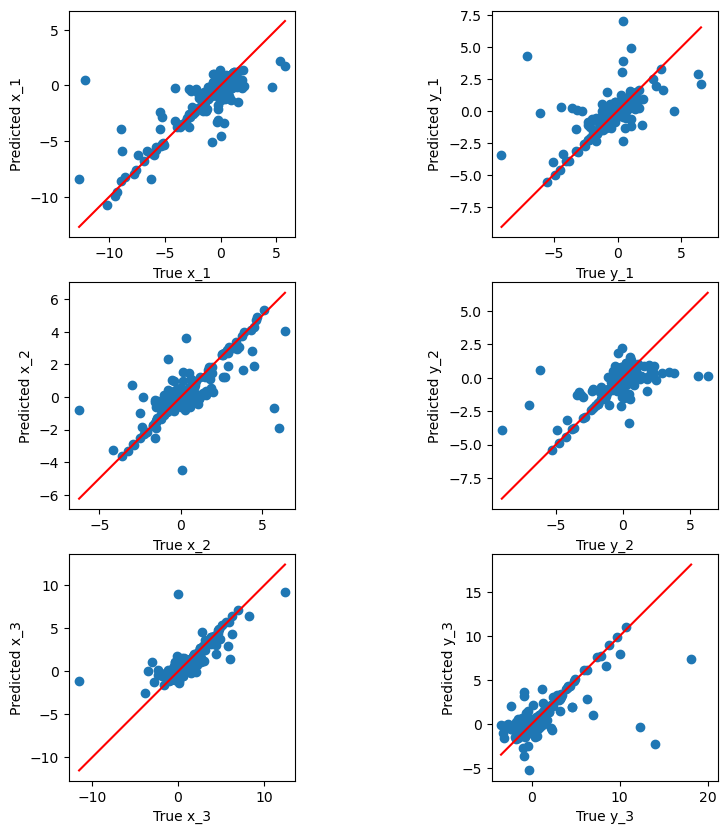

Test RMSE: 0.9753016803875235


In [40]:
y_test_pred_alt = std_model_alt.predict(X_test)

position_columns = ['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3']
y_test_pred_positions = y_test_pred_alt[:, range(6)]
y_test_positions = y_test[position_columns].values

plot_y_yhat(y_test_positions, y_test_pred_positions, plot_title="y_yhat_plot")
rmse = root_mean_squared_error(y_test_positions, y_test_pred_positions)

print(f"Test RMSE: {rmse}")

In [15]:
X_kaggle_df_knn = pd.read_csv('../mlNOVA/X_test.csv')
X_kaggle_df_knn.drop(columns=['Id'], inplace=True)

X_kaggle_df_knn = augment_dataset(X_kaggle_df_knn, enable_euclidian_dist=True, enable_angles=True, enable_polars=True)

In [43]:
# y_knn_std_pred = std_model.predict(X_kaggle_df_knn)

In [44]:
# targets = ['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3', 'dist_12', 'dist_23', 'dist_13', 'angle_1', 'angle_2', 'angle_3', 'r_1', 'theta_1', 'r_2', 'theta_2', 'r_3', 'theta_3']
# save_predictions(y_knn_std_pred, '../submissions/knn_submission.csv', targets)

In [18]:
y_knn_std_pred_alt = std_model_alt.predict(X_kaggle_df_knn)

In [19]:
targets = ['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3', 'dist_12', 'dist_23', 'dist_13', 'angle_1', 'angle_2', 'angle_3', 'r_1', 'theta_1', 'r_2', 'theta_2', 'r_3', 'theta_3']
save_predictions(y_knn_std_pred_alt, '../submissions/knn_submission.csv', targets)

C:\Users\rasvi\AppData\Local\Temp\ipykernel_28664\2381563791.py:139: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_positions['Id'] = df_positions.index


In [20]:
save_model(std_model_alt, "knn_std_k77_model.onnx", X_kaggle_df_knn)

<class 'sklearn.pipeline.Pipeline'>


MinMax scaler

In [45]:
minmax_model, minmax_k, minmax_rmse = validate_knn_regression(X_train, y_train, X_dev, y_dev, X_test, y_test, [1, 3, 5, 7], MinMaxScaler())

K is 1 | Validation RMSE: inf | Test RMSE: 0.9295229181363353
K is 3 | Validation RMSE: 1.1501327796778267 | Test RMSE: 0.9211226497066352
K is 5 | Validation RMSE: 1.1495448740278946 | Test RMSE: 0.9164944356415655
Best K: 5, Validation RMSE: 1.1469978529966902 | Test RMSE: 0.9164944356415655


In [7]:
minmax_model_alt, minmax_k_alt, minmax_rmse_alt = validate_knn_regression(X_train, y_train, X_dev, y_dev, X_test, y_test, [10, 20, 30, 40, 50, 75, 100], MinMaxScaler())

K is 10 | Validation RMSE: 1.1190432106999122 | Test RMSE: 0.9228998181957179
K is 20 | Validation RMSE: 1.0555452112361527 | Test RMSE: 0.9189265257834368
K is 30 | Validation RMSE: 1.0168234834757297 | Test RMSE: 0.9357341804887312
K is 40 | Validation RMSE: 1.0021113351101256 | Test RMSE: 0.947670971205798
K is 50 | Validation RMSE: 1.0021580857791945 | Test RMSE: 0.9656537187262028
K is 75 | Validation RMSE: 0.999397484517671 | Test RMSE: 0.9846085442886082
K is 100 | Validation RMSE: 0.9983831409707351 | Test RMSE: 0.9926532070664473
Best K: 100, Validation RMSE: 0.9983831409707351 | Test RMSE: 0.9926532070664473


In [46]:
# y_test_pred = minmax_model.predict(X_test)

# position_columns = ['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3']
# y_test_pred_positions = y_test_pred[:, range(6)]
# y_test_positions = y_test[position_columns].values

# rmse = root_mean_squared_error(y_test_positions, y_test_pred_positions)

# print(f"Test RMSE: {rmse}")

In [47]:
# y_knn_minmax_pred = minmax_model.predict(X_kaggle_df_knn)

In [48]:
# targets = ['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3', 'dist_12', 'dist_23', 'dist_13', 'angle_1', 'angle_2', 'angle_3', 'r_1', 'theta_1', 'r_2', 'theta_2', 'r_3', 'theta_3']
# save_predictions(y_knn_minmax_pred, '../submissions/knn_submission_minmax.csv', targets)